# Task 3: Build your own PINN


## Task 3.1

We chose the 1D heat equation:

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Physical parameters, we choose simple values to visualize the solution
L = 1.0         # rod length, x in [0, 1]
T = 1.0         # simulation time,  t in [0, 1]
alpha = 0.1     # thermal diffusivity constant

# Closed-form solution of 1D heat equation
def analytical_solution(x, t):
    return np.sin(np.pi * x / L) * np.exp(
        -alpha * (np.pi / L)**2 * t
    )

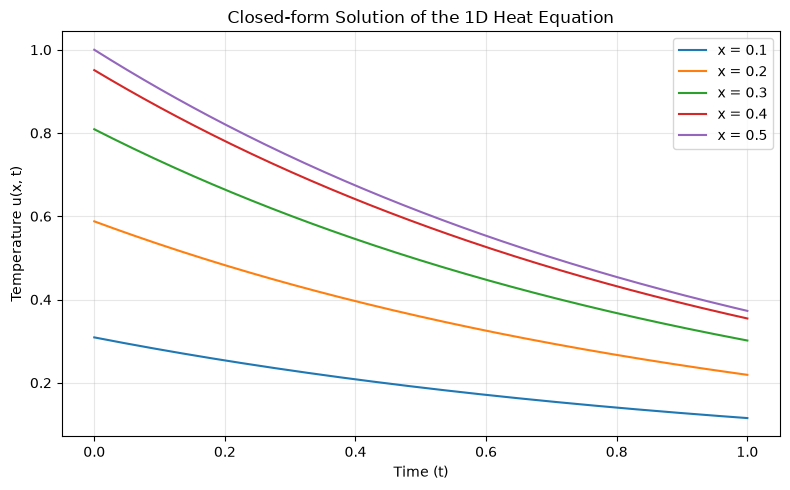

In [26]:
# Time points for evaluating the solution, we use 200 for a smooth curve
t = np.linspace(0, T, 200)

# Choose five positions along the first half of the rod (the solution is symmetric)
x_positions = [0.1, 0.2, 0.3, 0.4, 0.5]

plt.figure(figsize=(8, 5))

# Plot the temperature over time at each position
for x in x_positions:
    u = analytical_solution(x, t)
    plt.plot(t, u, label=f"x = {x:.1f}")

plt.xlabel("Time (t)")
plt.ylabel("Temperature u(x, t)")
plt.title("Closed-form Solution of the 1D Heat Equation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("task3-1.png", dpi=300, bbox_inches="tight")
plt.show()



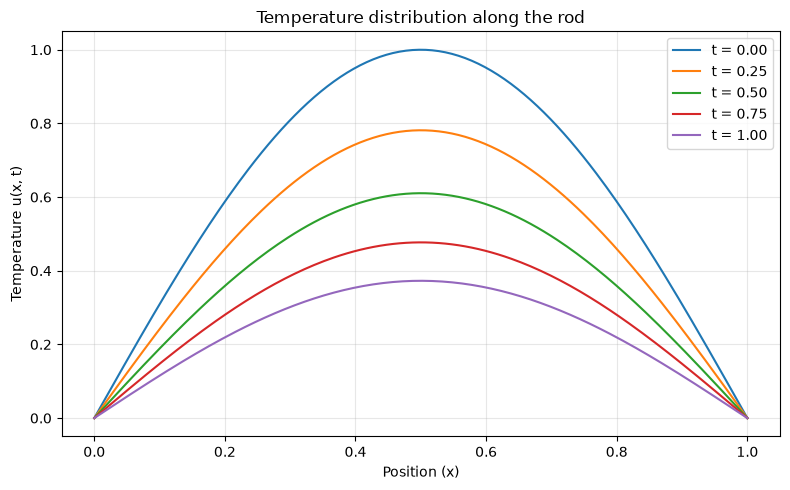

In [27]:
# Position points for evaluating the solution, we use 200 for a smooth curve
x = np.linspace(0, L, 200)

# Choose five times to show how the temperature changes
time_points = [0, 0.25, 0.5, 0.75, 1.0]

plt.figure(figsize=(8, 5))

# Plot the temperature along the rod at each time
for t in time_points:
    u = analytical_solution(x, t)
    plt.plot(x, u, label=f"t = {t:.2f}")

plt.xlabel("Position (x)")
plt.ylabel("Temperature u(x, t)")
plt.title("Temperature distribution along the rod")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Task 3.2.

For the PINN, the loss function consists of three terms: the physics loss, the initial-condition loss and the boundary-condition loss.

We derived the expressions for these three losses manually, calculated them, and also calculated their gradients to use them later for training.

## Task 3.3.

### Network definition

We use the same type of network as in task 2, but with two inputs instead of one. We kept 32 neurons and tanh activation since they were already used in task 2.


In [28]:

# One hidden layer of 32 neurons
H = 32

def init_params():
    p = {}
    p["Wx"] = np.random.randn(H)               # weights for x
    p["Wt"] = 0.5 * np.random.randn(H)         # weights for t
    p["b"] = np.zeros(H)                       # hidden biases
    p["v"] = np.random.randn(H) / np.sqrt(H)   # output weights
    p["c"] = np.zeros(1)                       # output bias
    return p


# Hidden layer and the derivatives of tanh with respect to its input a:
#   h = tanh(a)
#   s = dh/da   = 1 - h^2
#   g = d2h/da2 = -2 h (1 - h^2)
#   k = d3h/da3 = (6 h^2 - 2)(1 - h^2)
def hidden(p, x, t):
    a = np.outer(x, p["Wx"]) + np.outer(t, p["Wt"]) + p["b"]
    h = np.tanh(a)
    s = 1 - h**2
    g = -2 * h * s
    k = (6 * h**2 - 2) * s
    return h, s, g, k

def f_theta(p, x, t):
    h = np.tanh(np.outer(x, p["Wx"]) + np.outer(t, p["Wt"]) + p["b"])
    return h @ p["v"] + p["c"]

### Loss functions and gradients
Gradients were calculated manually to use them directly without using autograd

#### Physics residual and gradients

In [29]:
# Residual r_theta = u_t - alpha * u_xx, with
#   u_t  = sum_j v_j * Wt_j * s_j
#   u_xx = sum_j v_j * Wx_j^2 * g_j
# Returns the residual and its gradients for every parameter

def residual_and_grads(p, x, t):
    h, s, g, k = hidden(p, x, t)
    v, Wx, Wt = p["v"], p["Wx"], p["Wt"]

    u_t = (s * Wt) @ v
    u_xx = (g * Wx**2) @ v
    r_theta = u_t - alpha * u_xx

    phi = s * Wt - alpha * g * Wx**2        
    D = v * (g * Wt - alpha * k * Wx**2)    

    dr = {}
    dr["v"] = phi
    dr["c"] = np.zeros((len(x), 1))
    dr["b"] = D
    dr["Wx"] = x[:, None] * D - 2 * alpha * v * Wx * g
    dr["Wt"] = t[:, None] * D + v * s

    return r_theta, dr

#### Initial and boundary conditions

In [30]:

# Value of the network output and its gradients
# Used later for the initial and boundary conditions

def u_and_grads(p, x, t):
    h, s, g, k = hidden(p, x, t)
    v = p["v"]

    u = h @ v + p["c"]

    du = {}
    du["v"] = h
    du["c"] = np.ones((len(x), 1))
    du["b"] = v * s
    du["Wx"] = x[:, None] * v * s
    du["Wt"] = t[:, None] * v * s

    return u, du

#### Total loss function

In [31]:

# Total loss = lambda_phys * loss_phys + lambda_IC * loss_IC + lambda_BC * loss_BC
# We use the gradients of each term to calculate the total gradient

def total_loss_and_grads(p, data, lambda_phys=1.0, lambda_IC=1.0, lambda_BC=1.0):
    grads = {key: np.zeros_like(val) for key, val in p.items()}

    # Physics loss
    r_theta, dr = residual_and_grads(p, data["x_col"], data["t_col"])
    loss_phys = np.mean(r_theta**2)

    for key in p:
        grads[key] += lambda_phys * np.mean(2 * r_theta[:, None] * dr[key], axis=0)

    # Initial condition loss
    u, du = u_and_grads(p, data["x_ic"], data["t_ic"])
    r = u - data["u_ic"]
    loss_IC = np.mean(r**2)

    for key in p:
        grads[key] += lambda_IC * np.mean(2 * r[:, None] * du[key], axis=0)

    # Boundary condition loss (target is 0 at x = 0 and x = L)
    loss_BC = 0.0

    for x_b in [data["x_left"], data["x_right"]]:
        u, du = u_and_grads(p, x_b, data["t_bc"])
        loss_BC += np.mean(u**2)

        for key in p:
            grads[key] += lambda_BC * np.mean(2 * u[:, None] * du[key], axis=0)

    total = (lambda_phys * loss_phys + lambda_IC * loss_IC + lambda_BC * loss_BC)

    return total, loss_phys, loss_IC, loss_BC, grads


#### Training and evaluation points

We use a 30x30 grid of collocation points to evaluate the physics loss.

For the initial condition we define 100 points, also 100 time points for the boundary conditions at both ends of the rod.

We also compared 20x20, 30x30 and 40x40 grids. The differences in the L2 error were relatively small, so we kept the 30x30 grid.


In [32]:

# Training points (grid)
nx, nt = 30, 30
Xg, Tg = np.meshgrid(np.linspace(0, L, nx), np.linspace(0, T, nt))
x_ic = np.linspace(0, L, 100)
t_bc = np.linspace(0, T, 100)

data = {
    "x_col": Xg.flatten(), "t_col": Tg.flatten(),          # collocation points
    "x_ic": x_ic, "t_ic": np.zeros_like(x_ic),             # initial condition points
    "u_ic": np.sin(np.pi * x_ic / L),
    "x_left": np.zeros_like(t_bc), "x_right": L * np.ones_like(t_bc),  # boundary points
    "t_bc": t_bc,
}

# Test grid for the L2 error
Xt, Tt = np.meshgrid(np.linspace(0, L, 100), np.linspace(0, T, 100))
u_test_exact = analytical_solution(Xt, Tt).flatten()

def rel_l2_error(p):
    u_pred = f_theta(p, Xt.flatten(), Tt.flatten())
    return np.linalg.norm(u_pred - u_test_exact) / np.linalg.norm(u_test_exact)


In [33]:

# Gradient check: compare hand-derived gradients with finite differences
# to check if they have been implemented correctly
np.random.seed(0)
p = init_params()
_, _, _, _, grads = total_loss_and_grads(p, data)

eps = 1e-6
for key in ["Wx", "Wt", "b", "v", "c"]:
    idx = 3 if key != "c" else 0
    old = p[key][idx]
    p[key][idx] = old + eps
    loss_plus = total_loss_and_grads(p, data)[0]
    p[key][idx] = old - eps
    loss_minus = total_loss_and_grads(p, data)[0]
    p[key][idx] = old
    fd = (loss_plus - loss_minus) / (2 * eps)
    print(key, "hand:", grads[key][idx], "finite diff:", fd)


Wx hand: -0.037372243843823635 finite diff: -0.037372243855138265
Wt hand: -0.05796478342862629 finite diff: -0.0579647835285968
b hand: -0.1047670507648223 finite diff: -0.10476705092354877
v hand: -3.231327692685225 finite diff: -3.231327692865271
c hand: -3.9273148562617646 finite diff: -3.9273148564333837


#### Adam training

We implemented Adam manually using the gradients calculated. We also tried different learning rates and numbers of epochs. Since we observed some spikes during training, we decided to reduce the learning rate after 5,000 epochs.


We save the losses and relative L2 error to compare the results

In [34]:
# Training loop with Adam (written by hand too)
np.random.seed(42)
p = init_params()

m = {key: np.zeros_like(val) for key, val in p.items()}
v_adam = {key: np.zeros_like(val) for key, val in p.items()}
lr, beta1, beta2, eps_adam = 1e-3, 0.9, 0.999, 1e-8
epochs = 50000

hist_total, hist_phys, hist_IC, hist_BC = [], [], [], []
hist_l2, hist_l2_epochs = [], []

for epoch in range(1, epochs + 1):
    # Reduce the learning rate after 5000 epochs
    if epoch <= 5000:
        lr = 1e-3
    else:
        lr = 5e-4

    total, loss_phys, loss_IC, loss_BC, grads = total_loss_and_grads(p, data)

    # Adam update
    for key in p:
        m[key] = beta1 * m[key] + (1 - beta1) * grads[key]
        v_adam[key] = beta2 * v_adam[key] + (1 - beta2) * grads[key]**2
        m_hat = m[key] / (1 - beta1**epoch)
        v_hat = v_adam[key] / (1 - beta2**epoch)
        p[key] = p[key] - lr * m_hat / (np.sqrt(v_hat) + eps_adam)

    # Save losses after updating the weights
    total, loss_phys, loss_IC, loss_BC, _ = total_loss_and_grads(p, data)
    hist_total.append(total)
    hist_phys.append(loss_phys)
    hist_IC.append(loss_IC)
    hist_BC.append(loss_BC)

    if epoch % 50 == 0:
        hist_l2.append(rel_l2_error(p))
        hist_l2_epochs.append(epoch)
    if epoch % 5000 == 0:
        print("epoch", epoch, "loss", total, "L2 error", hist_l2[-1])

# Save the model trained with Adam
p_adam = {key: val.copy() for key, val in p.items()}
adam_loss = total_loss_and_grads(p_adam, data)[0]
adam_l2 = rel_l2_error(p_adam)

print("Final Adam loss:", adam_loss)
print("Final relative L2 error:", adam_l2)

epoch 5000 loss 0.0001569102309099019 L2 error 0.003393084176597165
epoch 10000 loss 6.743127921413418e-05 L2 error 0.002033076675494136
epoch 15000 loss 4.392116782734032e-05 L2 error 0.0015586518470043602
epoch 20000 loss 3.3070144300479735e-05 L2 error 0.0013087624481967074
epoch 25000 loss 2.6488232430571464e-05 L2 error 0.001147821740047697
epoch 30000 loss 2.1842259214377636e-05 L2 error 0.001025430234036597
epoch 35000 loss 1.8195708711866284e-05 L2 error 0.000918250791558389
epoch 40000 loss 1.5090362969918439e-05 L2 error 0.0008095089758409078
epoch 45000 loss 1.2367453409478864e-05 L2 error 0.0006806889192454221
epoch 50000 loss 1.0030910219299158e-05 L2 error 0.0005501169941512521
Final Adam loss: 1.0030910219299158e-05
Final relative L2 error: 0.0005501169941512521


#### Improve with L-BFGS-B
After training with Adam, we use L-BFGS-B to see if the predictions can be further improved. We chose this optimizer because we already used it in Task 2 and wanted to see if it could also improve the results here.

As in Task 2, we use SciPy's minimize function, which requires the network parameters and gradients as vectors. For this, we use flatten and unflatten functions to convert between the parameter dictionary and a single vector.

We start from the weights obtained with Adam and run L-BFGS-B for up to 1,000 iterations.

In [35]:

from scipy.optimize import minimize

# L-BFGS-B needs all the parameters in one vector
keys = list(p_adam.keys())
shapes = {key: p_adam[key].shape for key in keys}
sizes = {key: p_adam[key].size for key in keys}

def flatten_params(p):
    return np.concatenate([p[key].ravel() for key in keys])

def unflatten_params(theta):
    p = {}
    start = 0
    for key in keys:
        end = start + sizes[key]
        p[key] = theta[start:end].reshape(shapes[key])
        start = end
    return p

# Loss and gradients for L-BFGS-B
def objective(theta):
    p = unflatten_params(theta)
    loss, _, _, _, grads = total_loss_and_grads(p, data)
    return loss, flatten_params(grads)

# Save losses and L2 errors
lbfgs_losses, lbfgs_l2 = [], []

def callback(theta):
    p = unflatten_params(theta)
    loss = total_loss_and_grads(p, data)[0]
    l2 = rel_l2_error(p)
    lbfgs_losses.append(loss)
    lbfgs_l2.append(l2)

    if len(lbfgs_losses) % 100 == 0:
        print("iteration", len(lbfgs_losses), "loss", loss, "L2 error", l2)

# Train with L-BFGS-B starting from the Adam weights
result = minimize(
    objective,
    flatten_params(p_adam),
    method="L-BFGS-B",
    jac=True,
    callback=callback,
    options={"maxiter": 1000, "ftol": 1e-12, "gtol": 1e-10, "maxls": 30}
)

p_lbfgs = unflatten_params(result.x)
lbfgs_loss = total_loss_and_grads(p_lbfgs, data)[0]
lbfgs_error = rel_l2_error(p_lbfgs)

# Compare both optimizers
print("\nAdam loss:", adam_loss)
print("Adam + L-BFGS-B loss:", lbfgs_loss)
print("Adam L2 error:", adam_l2)
print("Adam + L-BFGS-B L2 error:", lbfgs_error)
print("L-BFGS-B iterations:", result.nit)
print("Optimizer message:", result.message)

# Find the iteration with the lowest L2 error
best_idx = np.argmin(lbfgs_l2)
print("Best L-BFGS-B iteration:", best_idx + 1)
print("Best relative L2 error:", lbfgs_l2[best_idx])


iteration 100 loss 8.00240686817524e-06 L2 error 0.000597298330279738
iteration 200 loss 6.38418137825618e-06 L2 error 0.0003495723801003986
iteration 300 loss 5.940930440495745e-06 L2 error 0.00024253733299789304
iteration 400 loss 5.602534336215294e-06 L2 error 0.00024061526324612942
iteration 500 loss 5.233886828476633e-06 L2 error 0.00022310573354626185
iteration 600 loss 5.044033695678518e-06 L2 error 0.00026758612586176816
iteration 700 loss 4.616796224663368e-06 L2 error 0.000306033137096877
iteration 800 loss 4.463379061393771e-06 L2 error 0.00032518989254686853
iteration 900 loss 4.190634264780582e-06 L2 error 0.00034277198912948303
iteration 1000 loss 3.858423694845487e-06 L2 error 0.00041331286435335304

Adam loss: 1.0030910219299158e-05
Adam + L-BFGS-B loss: 3.858423694845487e-06
Adam L2 error: 0.0005501169941512521
Adam + L-BFGS-B L2 error: 0.00041331286435335304
L-BFGS-B iterations: 1000
Optimizer message: STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT
Best L-BFGS-B iteratio

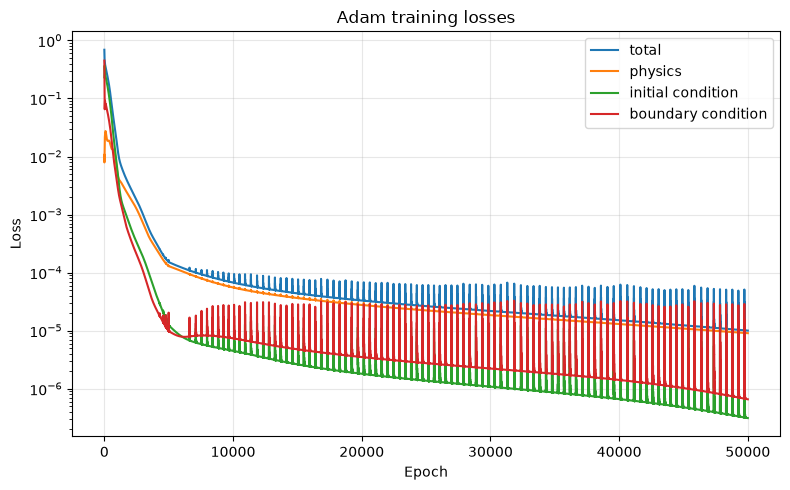

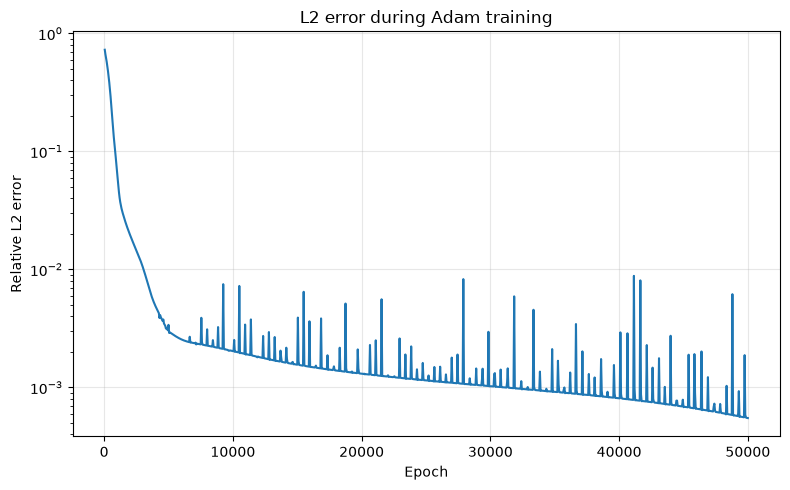

In [36]:
# Save the models and figures
np.savez("task3-adam.npz", **p_adam)
np.savez("task3-lbfgsb.npz", **p_lbfgs)


# Plot the loss curves during Adam training
plt.figure(figsize=(8, 5))
plt.semilogy(hist_total, label="total")
plt.semilogy(hist_phys, label="physics")
plt.semilogy(hist_IC, label="initial condition")
plt.semilogy(hist_BC, label="boundary condition")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Adam training losses")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("task3-3-loss.png", dpi=300, bbox_inches="tight")
plt.show()

# Plot the relative L2 error during Adam training
plt.figure(figsize=(8, 5))
plt.semilogy(hist_l2_epochs, hist_l2)
plt.xlabel("Epoch")
plt.ylabel("Relative L2 error")
plt.title("L2 error during Adam training")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("task3-3-l2.png", dpi=300, bbox_inches="tight")
plt.show()


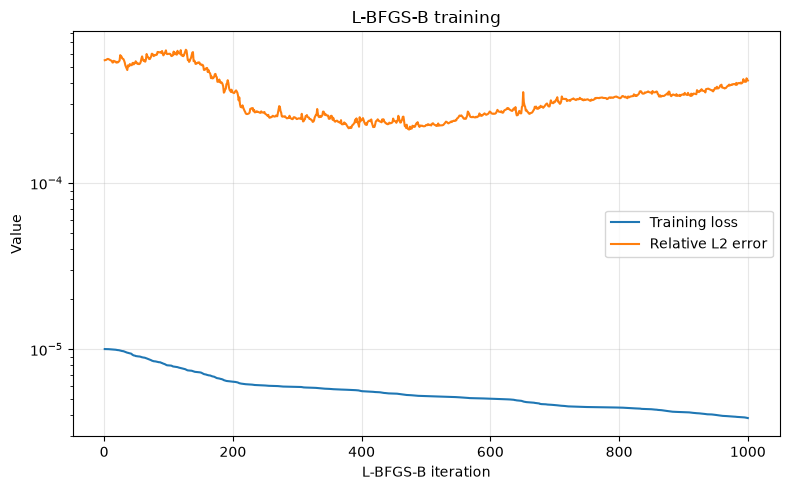

In [37]:
# Plot loss and L2 error during L-BFGS-B 
plt.figure(figsize=(8, 5))
plt.semilogy(np.arange(1, len(lbfgs_losses) + 1), lbfgs_losses, label="Training loss")
plt.semilogy(np.arange(1, len(lbfgs_l2) + 1), lbfgs_l2, label="Relative L2 error")
plt.xlabel("L-BFGS-B iteration")
plt.ylabel("Value")
plt.title("L-BFGS-B training")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("task3-3-lbfgsb-refinement.png", dpi=300, bbox_inches="tight")
plt.show()


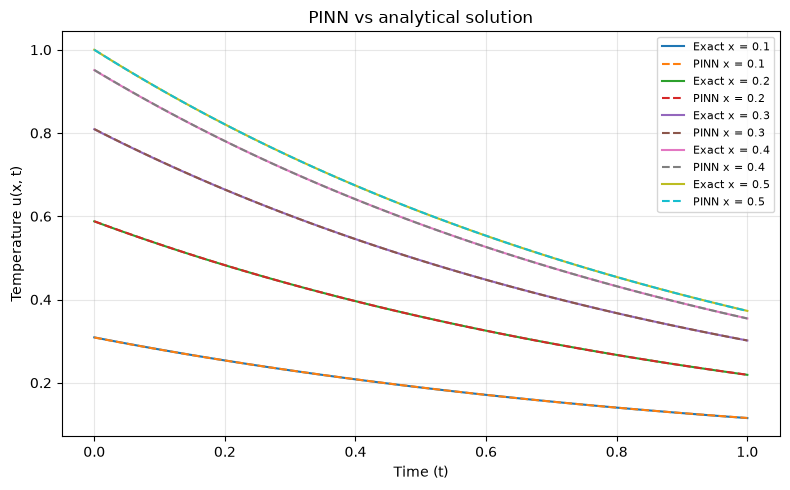

In [38]:

# Compare the PINN with the analytical solution
t_line = np.linspace(0, T, 100)

plt.figure(figsize=(8, 5))
for x0 in x_positions:
    plt.plot(t_line, analytical_solution(x0, t_line), label=f"Exact x = {x0}")
    plt.plot(t_line, f_theta(p_lbfgs, x0 * np.ones_like(t_line), t_line), "--", label=f"PINN x = {x0}")

plt.xlabel("Time (t)")
plt.ylabel("Temperature u(x, t)")
plt.title("PINN vs analytical solution")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("task3-3-comparison.png", dpi=300, bbox_inches="tight")
plt.show()
